# 03 – Section 6.3.5: life calculation with Multiax-Invariant

Recomputes Table 6.5 and Figures 6.45–6.56 of the dissertation.
* Local stresses at the inner root notch (Tab. 6.1): $\sigma_x = 61.0\,F$, $\sigma_y = 19.9\,F$ (MPa/kN), $\tau_{xy} = 1.1\,M_t$ (MPa/Nm).
* Base S-N curves: normed curves of Tab. 3.8, converted to the equivalent stress amplitude. The 90° curve is the calibration curve of $d_{PV}(F_{PV})$.
* Constant amplitudes: Weg A1/A2 with $k^* = 22$. Variable amplitudes: Weg B, Haibach $k' = 2k-2$, $D_{zul} = 0.5$.
  The Gauss sequence is synthesized (notebook 02), so the variable-amplitude results are approximate.
* Equivalent stress amplitudes $\sigma_{e,a}^{(I)}$ (5.4) and $\sigma_{e,a}^{(II)}$ (5.5).

Runouts in the boxplots: **preliminary** policy `exclude_DL` (DL only plotted, hDL counted). The author will confirm it.

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mxpy.data import load_params, load_tests, include_in_statistics, LOADCASES, COLORS
from mxpy.multiax_invariant import (MIModel, sigma_e_I, sigma_e_II, f_I, sigma_a_max, tau_a_max, shear_hull,
                                    F_PV_cycles)
from mxpy.stress import w_shear, quad
from mxpy.stats import covariance_full, cycle_covariances
from mxpy.sequence import gauss_reversals, local_channels
from mxpy.rainflow import ModifiedRainflow
from mxpy import plotting

P = load_params()
df = load_tests()
RUNOUT_POLICY = 'exclude_DL'   # PRELIMINARY, see mxpy.data.include_in_statistics
tf = P['transfer_factors_tab_6_1']['inner']
r = P['Mt_over_F']

## Table 6.5 – load characteristics per unit load

In [2]:
m2 = MIModel(P, 'II', 'CA')
cases = [('reine Axiallast, F_a = 1 kN', 1, 0, 0, (17.17, 25.04, 0.50, 0.0)),
         ('reine Torsion, M_t,a = 28 Nm', 0, 28, 0, (8.32, 12.69, 1.00, 0.0)),
         ('komb., δ = 0°', 1, 28, 0, (17.17, 28.08, 0.50, 0.0)),
         ('komb., δ = 90°', 1, 28, 90, (19.56, 28.08, 0.50, 4430.90)),
         ('komb., δ = 45°', 1, 28, 45, (18.71, 28.08, 0.48, 3133.12))]
rows = []
for name, F, M, d, ref in cases:
    C = m2.cov(F, M, d)
    rows.append(dict(Belastung=name, sI=float(sigma_e_I(C)), sII=float(sigma_e_II(C)), f_I=float(f_I(C)),
                     F_PV=m2.F_PV_CA(F, M, d), sI_tab=ref[0], sII_tab=ref[1], f_I_tab=ref[2], F_PV_tab=ref[3]))
t65 = pd.DataFrame(rows)
display(t65.round(3))
assert np.allclose(t65.sI, t65.sI_tab, atol=0.006) and np.allclose(t65.sII, t65.sII_tab, atol=0.006)
assert np.allclose(t65.F_PV, t65.F_PV_tab, atol=0.5)
print('Table 6.5: sigma_e^(I), sigma_e^(II), F_PV reproduced (±0.01 MPa, ±0.5).')

,Belastung,sI,sII,f_I,F_PV,sI_tab,sII_tab,f_I_tab,F_PV_tab
0,"reine Axiallast, F_a = 1 kN",17.168,25.045,0.500,0.000,17.17,25.04,0.50,0.00
1,"reine Torsion, M_t,a = 28 Nm",8.322,12.690,1.000,0.000,8.32,12.69,1.00,0.00
2,"komb., δ = 0°",17.168,28.076,0.500,0.000,17.17,28.08,0.50,0.00
3,"komb., δ = 90°",19.560,28.076,0.505,4430.901,19.56,28.08,0.50,4430.90
4,"komb., δ = 45°",18.711,28.076,0.500,3133.120,18.71,28.08,0.48,3133.12


Table 6.5: sigma_e^(I), sigma_e^(II), F_PV reproduced (±0.01 MPa, ±0.5).


### Note on $f_I$ (Table 6.5)
The full search of (D.57) over all planes and directions ($\theta, \psi, \xi$) gives $f_I(45°) = 0.50$. Table 6.5 lists 0.48.
0.48 is obtained if the shear search is restricted to planes with $\psi = 0$, but the same restriction gives $f_I(0°) = 0.478$ instead of the tabulated 0.50.
This is relevant only for the documentation. For $f_I \le 0.5$ the axial S-N curve is used, so the life is the same.

In [3]:
TH, XI = np.meshgrid(np.linspace(0, np.pi, 721), np.linspace(0, np.pi, 721))
w_in = w_shear(TH.ravel(), np.zeros(TH.size), XI.ravel())
for name, F, M, d, ref in cases:
    C = m2.cov(F, M, d)
    s = float(sigma_a_max(C))
    print(f'{name:32s} f_I (D.57, full) = {float(tau_a_max(C)) / s:.4f}   f_I (psi = 0 only) = {np.sqrt(2 * quad(w_in, C).max()) / s:.4f}   Tab. 6.5: {ref[2]}')

reine Axiallast, F_a = 1 kN      f_I (D.57, full) = 0.5000   f_I (psi = 0 only) = 0.3369   Tab. 6.5: 0.5
reine Torsion, M_t,a = 28 Nm     f_I (D.57, full) = 1.0000   f_I (psi = 0 only) = 1.0000   Tab. 6.5: 1.0


komb., δ = 0°                    f_I (D.57, full) = 0.5000   f_I (psi = 0 only) = 0.4779   Tab. 6.5: 0.5
komb., δ = 90°                   f_I (D.57, full) = 0.5049   f_I (psi = 0 only) = 0.5049   Tab. 6.5: 0.5
komb., δ = 45°                   f_I (D.57, full) = 0.5000   f_I (psi = 0 only) = 0.4798   Tab. 6.5: 0.48


## Constant amplitudes (Weg A1/A2) – Figures 6.45–6.50

sigma_e^(I): axial knee 30.73 MPa, torsion knee 20.45 MPa, 90° calibration knee 25.23 MPa, f_I(90°) = 0.505
sigma_e^(II): axial knee 44.83 MPa, torsion knee 31.18 MPa, 90° calibration knee 36.22 MPa, f_I(90°) = 0.505


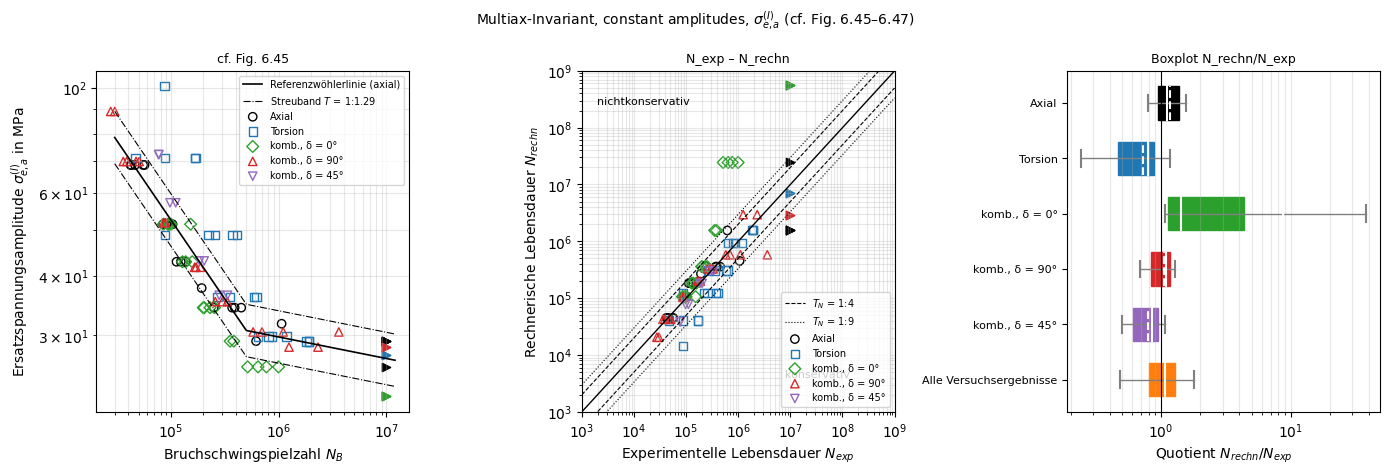

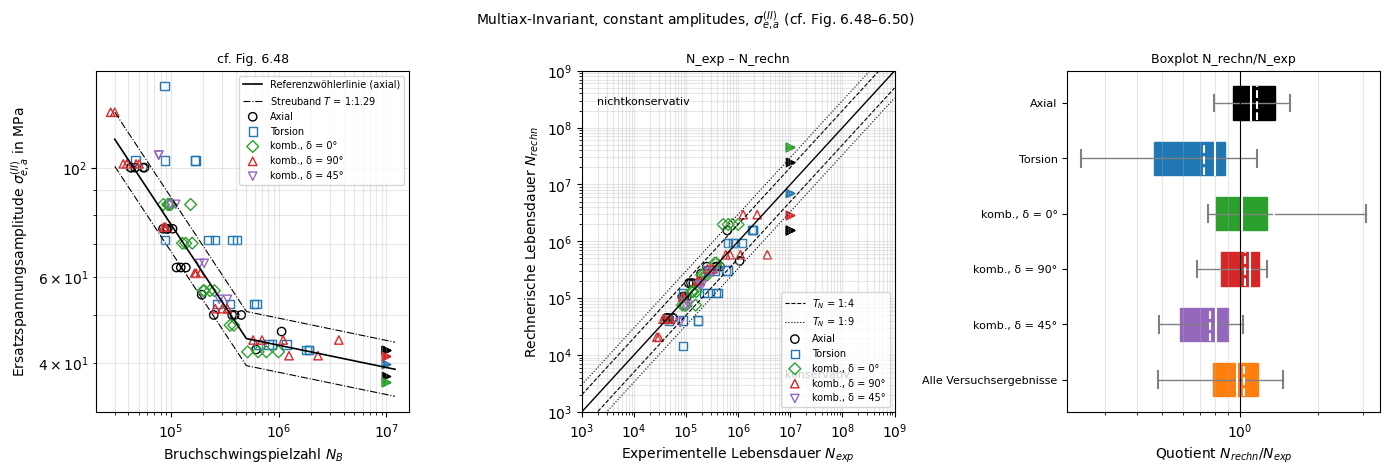

In [4]:
ca = df[df.amp == 'CA'].reset_index(drop=True)
mask_ca = include_in_statistics(ca, RUNOUT_POLICY)
res_ca = {}
for meas in ('I', 'II'):
    model = MIModel(P, meas, 'CA')
    out = np.array([model.life_CA(Fa, Mt, d) for Fa, Mt, d in zip(ca.F_a, ca.M_ta, ca.delta)])
    res_ca[meas] = dict(model=model, N=out[:, 0], se=out[:, 1], fI=out[:, 2], fpv=out[:, 3],
                        y=model.reference_amplitude(out[:, 0]))
    print(f'sigma_e^({meas}): axial knee {model.sn_ax.L_k:.2f} MPa, torsion knee {model.sn_tors.L_k:.2f} MPa, '
          f'90° calibration knee {model.sn_d90.L_k:.2f} MPa, f_I(90°) = {model.fI90:.3f}')

stats_ca = {}
for meas, figs in (('I', '6.45–6.47'), ('II', '6.48–6.50')):
    R = res_ca[meas]
    fig = plt.figure(figsize=(14, 4.8))
    ax1 = fig.add_subplot(1, 3, 1); ax2 = fig.add_subplot(1, 3, 2); ax3 = fig.add_subplot(1, 3, 3)
    plotting.sn_plot(ax1, ca, R['y'], R['model'].sn_ax, T=P['scatter_band_reference_T'],
                     ylabel=fr'Ersatzspannungsamplitude $\sigma_{{e,a}}^{{({meas})}}$ in MPa', title=f'cf. Fig. {figs.split("–")[0]}')
    plotting.nn_plot(ax2, ca, R['N'], title='N_exp – N_rechn')
    stats_ca[meas] = plotting.boxplot(ax3, ca, R['N'], mask_ca, title='Boxplot N_rechn/N_exp')
    fig.suptitle(fr'Multiax-Invariant, constant amplitudes, $\sigma_{{e,a}}^{{({meas})}}$ (cf. Fig. {figs})', fontsize=10)
    plt.tight_layout(); plt.show()

### Boxplot statistics (constant amplitudes)

In [5]:
def stats_table(stats):
    rows = []
    for meas, st_m in stats.items():
        for g_, st in st_m.items():
            rows.append(dict(measure=meas, group=g_, n=st['n'], q10=st[0.1], q25=st[0.25], median=st[0.5],
                             q75=st[0.75], q90=st[0.9], mean=st['mean']))
    return pd.DataFrame(rows)

box_ca = stats_table(stats_ca)
display(box_ca.round(2))

,measure,group,n,q10,q25,median,q75,q90,mean
0,I,ax,20,0.79,0.94,1.10,1.37,1.56,1.17
1,I,tors,21,0.24,0.46,0.80,0.88,1.17,0.72
2,I,d0,19,1.06,1.14,1.44,4.40,38.03,8.80
3,I,d90,21,0.68,0.84,1.10,1.18,1.27,1.05
4,I,d45,8,0.50,0.60,0.84,0.94,1.07,0.79
5,I,all,89,0.48,0.80,1.06,1.27,1.80,2.63
6,II,ax,20,0.79,0.94,1.10,1.37,1.56,1.17
7,II,tors,21,0.24,0.46,0.80,0.88,1.17,0.72
8,II,d0,19,0.75,0.81,1.02,1.28,3.08,1.35
9,II,d90,21,0.68,0.84,1.10,1.18,1.27,1.05


## Variable amplitudes (Weg B) – Figures 6.51–6.56
For each load type the cycles are identified once, for the unit load ($\bar F_a$ = 1 kN and/or $\bar M_{t,a}$ = 28 Nm):
critical plane and direction (D.82), modified rainflow count, then per cycle $C$: covariances, $\sigma_{e,a}^{(I/II)}$, $f_I$ and $F_{PV}$.
For a test level $s$, $\sigma_{e,a}$ scales with $s$ and $F_{PV}$ with $s^2$, while $f_I$ stays the same.
Then $D_{TF} = \sum_C d_C$ and $N_{rechn} = N_{TF}/D_{TF}\cdot D_{zul}$ (D.85), (D.86).

In [6]:
p_seq = gauss_reversals(P['L_TF'], seed=1, n_classes=32)
hull = shear_hull(1.0)
unit_loads = {'ax': (1.0, 0.0, 0.0), 'tors': (0.0, r, 0.0), 'd0': (1.0, r, 0.0), 'd90': (1.0, r, 0.5)}
cyc = {}
for lc, (F, M, shift) in unit_loads.items():
    t0 = time.time()
    t, X, dX = local_channels(p_seq, F, M, tf['c_x'], tf['c_y'], tf['c_xy'], shift=shift, n_per=16)
    _, Cfull = covariance_full(t, X)
    _, th_c, ps_c, xi_c = hull.max_var(Cfull)                              # critical plane/direction (D.82)
    tau_c = X @ w_shear(th_c, ps_c, xi_c)                                  # tau_{theta_max, psi_max, xi_max}(t)
    rf = ModifiedRainflow(t, tau_c).run()                                  # Sec. 5.5
    means, C, L = cycle_covariances(t, X, rf.a, rf.b, rf.cid, rf.n_cycles)
    fpv = F_PV_cycles(t, X, dX, rf, means) if shift > 0 else np.zeros(rf.n_cycles)
    cyc[lc] = dict(n=rf.n_cycles, sI=sigma_e_I(C), sII=sigma_e_II(C), fI=f_I(C, hull), fpv=fpv,
                   crit=np.rad2deg([th_c, ps_c, xi_c]))
    print(f'{lc:5s}: {rf.n_cycles} cycles, critical (theta, psi, xi) = {np.round(cyc[lc]["crit"], 1)} deg, '
          f'f_I range [{cyc[lc]["fI"].min():.3f}, {cyc[lc]["fI"].max():.3f}], sum F_PV = {fpv.sum():.4g}, {time.time() - t0:.1f} s')

ax   : 50440 cycles, critical (theta, psi, xi) = [  0. -45.  90.] deg, f_I range [0.500, 0.500], sum F_PV = 0, 57.2 s


tors : 50440 cycles, critical (theta, psi, xi) = [0. 0. 0.] deg, f_I range [1.000, 1.000], sum F_PV = 0, 57.2 s


d0   : 50440 cycles, critical (theta, psi, xi) = [28. 45. 90.] deg, f_I range [0.500, 0.500], sum F_PV = 0, 57.1 s


d90  : 50440 cycles, critical (theta, psi, xi) = [87.  0.  0.] deg, f_I range [0.500, 0.637], sum F_PV = 2.135e+07, 58.1 s


Check for the proportional load types: $F_{PV} = 0$ by definition. The cycle count equals $L_{TF}-1$ = 50440 because of the construction of the sequence.

In [7]:
for lc in ('ax', 'tors', 'd0'):
    assert cyc[lc]['n'] == P['L_TF'] - 1, (lc, cyc[lc]['n'])
# numerical check on a subset: F_PV of proportional cycles vanishes
t, X, dX = local_channels(p_seq[:2001], 1.0, r, tf['c_x'], tf['c_y'], tf['c_xy'], shift=0.0, n_per=16)
rf_chk = ModifiedRainflow(t, X[:, 0]).run()
mch, _, _ = cycle_covariances(t, X, rf_chk.a, rf_chk.b, rf_chk.cid, rf_chk.n_cycles)
assert np.abs(F_PV_cycles(t, X, dX, rf_chk, mch)).max() < 1e-8
print('proportional cycles: F_PV = 0 (numerical check): OK')

proportional cycles: F_PV = 0 (numerical check): OK


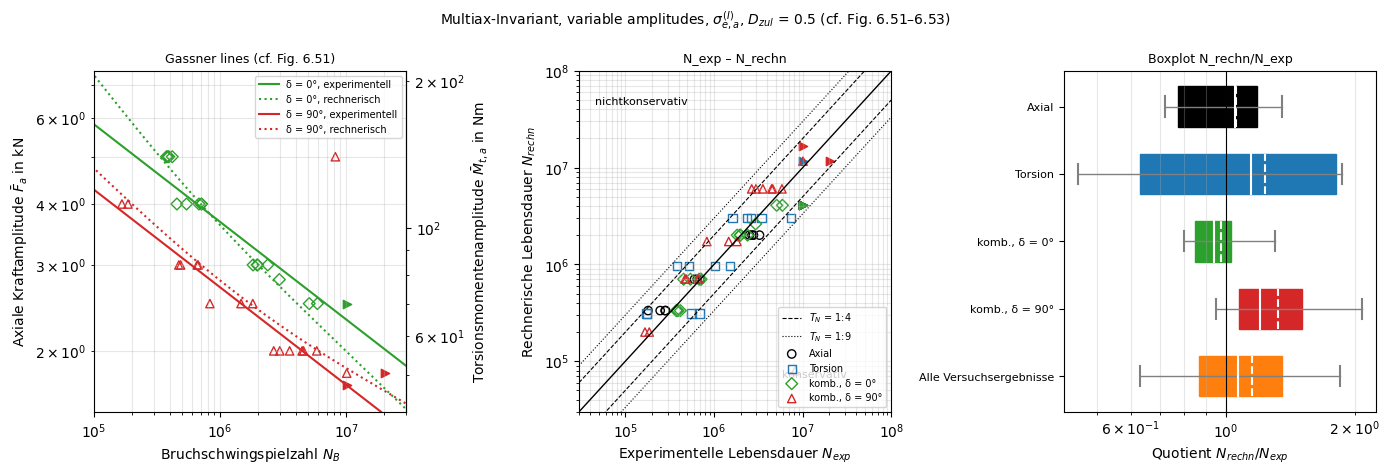

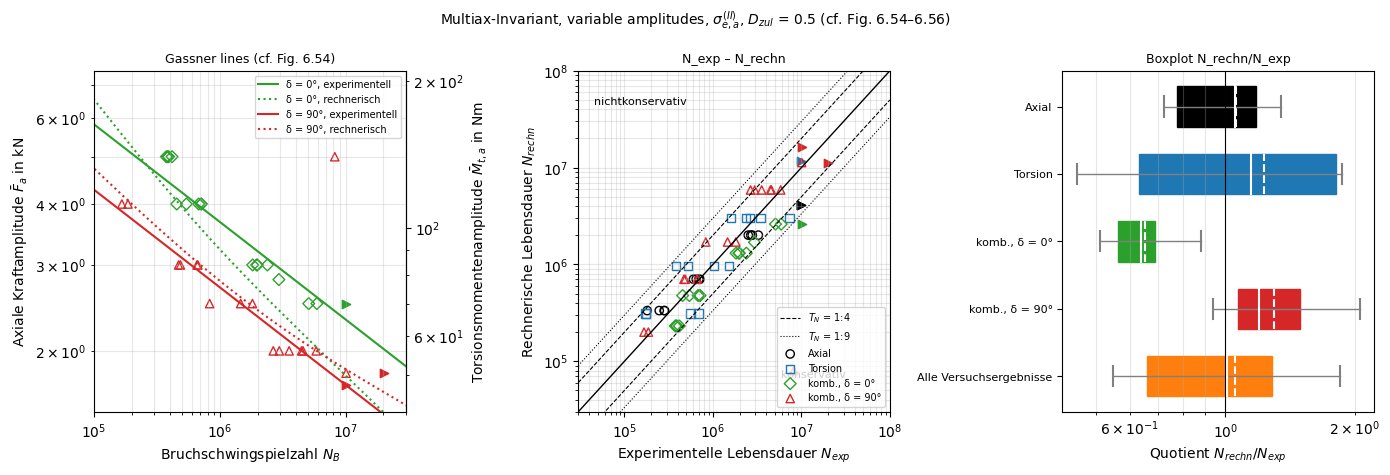

In [8]:
va = df[df.amp == 'VA'].reset_index(drop=True)
mask_va = include_in_statistics(va, RUNOUT_POLICY)


def scale_of(row):
    return row.M_ta / r if row.loadcase == 'tors' else row.F_a


def N_calc_VA(model, lc, s, meas):
    c = cyc[lc]
    se = c['s' + meas] * s
    d = model.damage(se, c['fI'], c['fpv'] * s ** 2)
    return c['n'] / d.sum() * P['D_zul']


res_va = {}
for meas in ('I', 'II'):
    model = MIModel(P, meas, 'VA')
    N = np.array([N_calc_VA(model, row.loadcase, scale_of(row), meas) for row in va.itertuples()])
    res_va[meas] = dict(model=model, N=N)

g = P['gassner_normed_tab_3_11']
s_grid = np.logspace(np.log10(1.5), np.log10(7.5), 40)
stats_va = {}
for meas, figs in (('I', '6.51–6.53'), ('II', '6.54–6.56')):
    model = res_va[meas]['model']
    lines = {}
    for lc, col in (('d0', 'tab:green'), ('d90', 'tab:red')):
        Nexp_line = g['N_A'] * (s_grid / g[lc]['L_A']) ** (-g[lc]['k'])
        lines[f'δ = {lc[1:]}°, experimentell'] = (Nexp_line, s_grid, col, '-')
        Ncalc_line = np.array([N_calc_VA(model, lc, s, meas) for s in s_grid])
        lines[f'δ = {lc[1:]}°, rechnerisch'] = (Ncalc_line, s_grid, col, ':')
    fig = plt.figure(figsize=(14, 4.8))
    ax1 = fig.add_subplot(1, 3, 1); ax2 = fig.add_subplot(1, 3, 2); ax3 = fig.add_subplot(1, 3, 3)
    plotting.gassner_plot(ax1, va, lines, r, title=f'Gassner lines (cf. Fig. {figs.split("–")[0]})')
    plotting.nn_plot(ax2, va, res_va[meas]['N'], lim=(3e4, 1e8), title='N_exp – N_rechn')
    stats_va[meas] = plotting.boxplot(ax3, va, res_va[meas]['N'], mask_va, title='Boxplot N_rechn/N_exp')
    fig.suptitle(fr'Multiax-Invariant, variable amplitudes, $\sigma_{{e,a}}^{{({meas})}}$, $D_{{zul}}$ = 0.5 (cf. Fig. {figs})', fontsize=10)
    plt.tight_layout(); plt.show()

In [9]:
box_va = stats_table(stats_va)
display(box_va.round(2))

,measure,group,n,q10,q25,median,q75,q90,mean
0,I,ax,12,0.72,0.77,1.05,1.18,1.35,1.06
1,I,tors,13,0.45,0.63,1.14,1.80,1.86,1.23
2,I,d0,16,0.80,0.85,0.94,1.03,1.30,0.98
3,I,d90,17,0.95,1.07,1.20,1.50,2.08,1.32
4,I,all,58,0.63,0.87,1.07,1.35,1.84,1.15
5,II,ax,12,0.72,0.77,1.05,1.18,1.35,1.06
6,II,tors,13,0.45,0.63,1.14,1.80,1.86,1.23
7,II,d0,16,0.51,0.56,0.64,0.69,0.88,0.65
8,II,d90,17,0.94,1.07,1.20,1.49,2.05,1.30
9,II,all,58,0.55,0.66,1.01,1.28,1.84,1.06


## Comparison with the statements of Section 6.3.5
Reading exact values off the printed boxplots is not reliable. The recomputation is therefore compared with the qualitative statements in the text of Section 6.3.5.

In [10]:
med = lambda tab, meas, g_: float(tab[(tab.measure == meas) & (tab.group == g_)]['median'].iloc[0])
checks = [
    ('CA, sigma^(I): delta=0 assessed non-conservatively', med(box_ca, 'I', 'd0') > 1.0),
    ('CA, sigma^(II) removes this (delta=0 closer to 1)', abs(np.log(med(box_ca, 'II', 'd0'))) < abs(np.log(med(box_ca, 'I', 'd0')))),
    ('CA: delta=90 close to the axial results', abs(np.log(med(box_ca, 'II', 'd90') / med(box_ca, 'II', 'ax'))) < np.log(1.3)),
    ('CA: delta=45 assessed conservatively', med(box_ca, 'II', 'd45') < 1.0 and med(box_ca, 'I', 'd45') < 1.0),
    ('VA, sigma^(I): delta=0 conservative', med(box_va, 'I', 'd0') <= 1.0),
    ('VA, sigma^(II) even more conservative for delta=0', med(box_va, 'II', 'd0') < med(box_va, 'I', 'd0')),
    ('VA: all load cases conservative or accurate (median <= ~1)', all(med(box_va, 'II', g_) <= 1.05 for g_ in ('ax', 'tors', 'd0', 'd90'))),
]
display(pd.DataFrame(checks, columns=['statement (Sec. 6.3.5)', 'reproduced']))

,statement (Sec. 6.3.5),reproduced
0,"CA, sigma^(I): delta=0 assessed non-conservati...",True
1,"CA, sigma^(II) removes this (delta=0 closer to 1)",True
2,CA: delta=90 close to the axial results,True
3,CA: delta=45 assessed conservatively,True
4,"VA, sigma^(I): delta=0 conservative",True
5,"VA, sigma^(II) even more conservative for delta=0",True
6,VA: all load cases conservative or accurate (m...,False


**Variable amplitudes – known deviation.** The recomputed VA lives are less conservative than in Fig. 6.51–6.56.
The order of magnitude is a factor 1.2 (axial) to about 2 (torsion, δ = 90°). Identified causes:
* The synthetic sequence is not the original one. The cycle amplitude of Multiax-Invariant is the variance-based amplitude $\sqrt{2\,\mathrm{Var}}$ over the cycle's
  intervals, and it depends on the waveform of the fragments. For the synthetic sequence it is about 0.94–0.98 of the rainflow amplitude, which gives about 15 % less damage than Miner with rainflow amplitudes.
* Amplitude classification of the sequence (32 classes): $D_{TF}$ is reproduced within about 7–10 % (notebook 02).

The remaining difference is not explained by these effects → **question to the author** (original sequence file? computation of $d_C$ per cycle?).

## Per-test results (for later use as a test oracle for the C++ implementation)

In [11]:
ca_out = ca[['table', 'specimen', 'loadcase', 'F_a', 'M_ta', 'delta', 'N_B', 'remark']].copy()
for meas in ('I', 'II'):
    ca_out[f'se_{meas}'] = res_ca[meas]['se']
    ca_out[f'N_calc_{meas}'] = res_ca[meas]['N']
ca_out['f_I'] = res_ca['II']['fI']
ca_out['F_PV'] = res_ca['II']['fpv']
va_out = va[['table', 'specimen', 'loadcase', 'F_a', 'M_ta', 'delta', 'N_B', 'remark']].copy()
for meas in ('I', 'II'):
    va_out[f'N_calc_{meas}'] = res_va[meas]['N']
os.makedirs('results', exist_ok=True)
ca_out.to_csv('results/mi_constant_amplitudes.csv', index=False)
va_out.to_csv('results/mi_variable_amplitudes.csv', index=False)
display(ca_out.head(12).round(3))
print('written: results/mi_constant_amplitudes.csv, results/mi_variable_amplitudes.csv')

,table,specimen,loadcase,F_a,M_ta,delta,N_B,remark,se_I,N_calc_I,se_II,N_calc_II,f_I,F_PV
0,A.2,AZ31-1.5-028,ax,4.0,0.0,0.0,42860,,68.670,4.480734e+04,100.178,4.480734e+04,0.5,0.0
1,A.2,AZ31-1.5-040,ax,4.0,0.0,0.0,56777,hDL,68.670,4.480734e+04,100.178,4.480734e+04,0.5,0.0
2,A.2,AZ31-1.5-011,ax,4.0,0.0,0.0,55119,hDL,68.670,4.480734e+04,100.178,4.480734e+04,0.5,0.0
3,A.2,AZ31-1.5-037,ax,3.0,0.0,0.0,84279,,51.503,1.062100e+05,75.134,1.062100e+05,0.5,0.0
4,A.2,AZ31-1.5-003,ax,3.0,0.0,0.0,90606,hDL,51.503,1.062100e+05,75.134,1.062100e+05,0.5,0.0
5,A.2,AZ31-1.5-031,ax,3.0,0.0,0.0,103360,hDL,51.503,1.062100e+05,75.134,1.062100e+05,0.5,0.0
6,A.2,AZ31-1.5-143,ax,2.5,0.0,0.0,137295,,42.919,1.835308e+05,62.612,1.835308e+05,0.5,0.0
7,A.2,AZ31-1.5-024,ax,2.0,0.0,0.0,249275,,34.335,3.584587e+05,50.089,3.584587e+05,0.5,0.0
8,A.2,AZ31-1.5-050,ax,2.0,0.0,0.0,369039,,34.335,3.584587e+05,50.089,3.584587e+05,0.5,0.0
9,A.2,AZ31-1.5-018,ax,1.7,0.0,0.0,615747,,29.185,1.555466e+06,42.576,1.555466e+06,0.5,0.0


written: results/mi_constant_amplitudes.csv, results/mi_variable_amplitudes.csv
